In [41]:
import sys, os
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import GridSearchCV
from xgboost import XGBClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.preprocessing import PowerTransformer
import matplotlib.pyplot as plt
from pathlib import Path
import seaborn as sns
import joblib

ROOT = Path.cwd().parent
sys.path.insert(0,str(ROOT))

#sys.path.insert(0, str(ROOT / 'src'))
from src.splits import get_cv_splits
from src.eval import evaluate_and_log
from src.features_freq import build_freq_table, FREQ_COLS

sns.set_theme(style='whitegrid')


In [3]:
os.environ['WANDB_ENTITY'] = 'emammadli'

In [ ]:
P = ROOT / 'data' / 'processed'
train = pd.read_csv(P / 'train_clean.csv')
test = pd.read_csv(P / 'test_clean.csv')
folds = pd.read_csv(P / 'folds.csv')
train = train.merge(folds[['record', 'minute', 'patient_fold', 'random_fold']], on=['record', 'minute'], validate='1:1')

print(train.shape)

BASE = ['rr_mean', 'rr_sdnn', 'rr_rmssd', 'rr_pnn50', 'rr_min', 'rr_max', 'rr_range']
Z = [c + '_z' for c in BASE]
CTX = [c + '_ctx' for c in Z]


FIG = ROOT / 'reports' / 'figures'

(16531, 27)


In [ ]:

# freq_train = build_freq_table(train)
# freq_test = build_freq_table(test)
# freq_train.to_csv(P / 'train_freq.csv', index=False)
# freq_test.to_csv(P / 'test_freq.csv', index=False)


In [ ]:
f_tr, f_te = P / 'train_freq.csv', P / 'test_freq.csv'

freq_train, freq_test = pd.read_csv(f_tr), pd.read_csv(f_te)

In [ ]:
print(freq_train.shape, freq_test.shape)
print(freq_train[FREQ_COLS].isna().sum().sum(), 'NaN')

(16531, 12) (16561, 12)
210 NaN


In [ ]:
na = freq_train[freq_train[FREQ_COLS].isna().any(axis=1)]
print(len(na), na.record.nunique())
print(na.groupby('record').minute.max().head())

21 21
record
a05    453
a06    509
a07    510
a08    500
a10    516
Name: minute, dtype: int64


In [ ]:
train = train.merge(pd.read_csv(P / 'train_freq.csv'), on=['record', 'minute'], validate='1:1')

med = train[FREQ_COLS].median()
train[FREQ_COLS] = train[FREQ_COLS].fillna(med)
print(train.shape, train[FREQ_COLS].isna().sum().sum(), 'NaN left')

(16531, 37) 0 NaN left


In [ ]:
train = train.sort_values(['record', 'minute']).reset_index(drop=True)
g = train.groupby('record')

FREQ_CTX = [f'{c}_ctx5' for c in FREQ_COLS]
train[FREQ_CTX] = g[FREQ_COLS].transform(lambda s: s.rolling(5, center=True, min_periods=1).mean())

FREQ_Z = [f'{c}_z' for c in FREQ_COLS]
train[FREQ_Z] = (train[FREQ_COLS] - g[FREQ_COLS].transform('mean')) / g[FREQ_COLS].transform('std')
FREQ_ZCTX = [f'{c}_zctx5' for c in FREQ_COLS]
train[FREQ_ZCTX] = train.groupby('record')[FREQ_Z].transform(
    lambda s: s.rolling(5, center=True, min_periods=1).mean())

## EDA Part For set E+ E+z

In [11]:
train[FREQ_COLS].describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
rr_vlf,16531.0,2.867,1.209,-1.903,2.050,2.963,3.712,6.167
rr_lf,16531.0,2.667,0.923,-2.271,2.128,2.762,3.297,5.641
rr_hf,16531.0,1.460,1.094,-3.397,0.775,1.531,2.238,4.716
rr_lf_hf,16531.0,1.206,0.960,-2.175,0.566,1.220,1.877,4.245
rr_vlf_frac,16531.0,0.473,0.213,0.017,0.292,0.475,0.650,0.959
edr_std,16531.0,0.415,0.270,0.041,0.215,0.366,0.561,5.737
edr_range,16531.0,1.303,0.833,0.000,0.680,1.149,1.770,12.000
edr_resp_rate,16531.0,13.479,3.788,6.328,11.250,13.359,15.469,29.883
edr_resp_frac,16531.0,0.590,0.193,0.007,0.458,0.630,0.734,0.963
edr_vlf_frac,16531.0,0.210,0.186,0.001,0.069,0.139,0.303,0.973


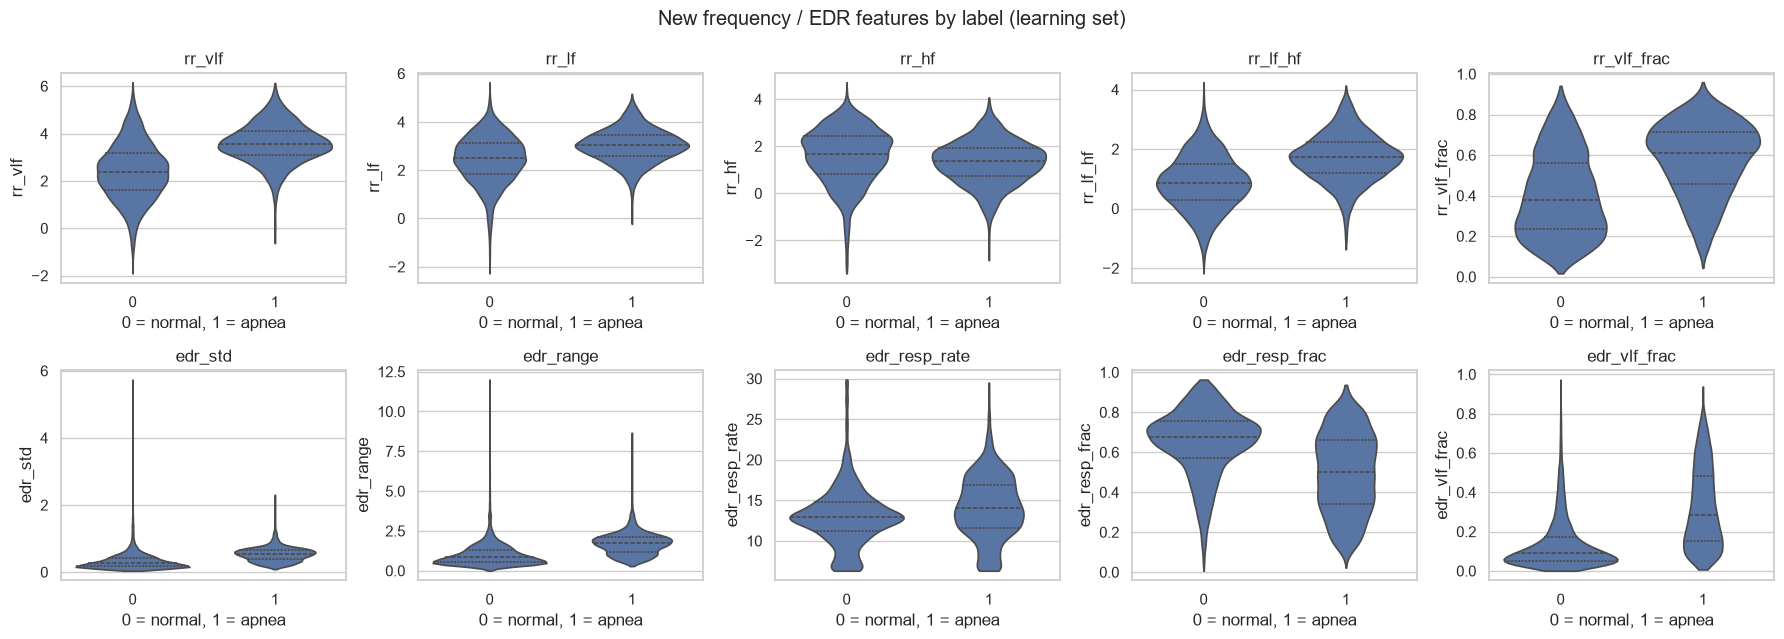

label,0,1
rr_vlf,2.384,3.573
rr_lf,2.492,3.030
rr_hf,1.681,1.352
rr_lf_hf,0.861,1.719
rr_vlf_frac,0.377,0.609
edr_std,0.266,0.536
edr_range,0.832,1.715
edr_resp_rate,13.008,14.062
edr_resp_frac,0.676,0.503
edr_vlf_frac,0.092,0.283


In [12]:
fig, axes = plt.subplots(2, 5, figsize=(18, 6.5))
for ax, col in zip(axes.flat, FREQ_COLS):
    sns.violinplot(data=train, x='label', y=col, ax=ax, cut=0, inner='quartile')
    ax.set_title(col); ax.set_xlabel('0 = normal, 1 = apnea')
plt.suptitle('New frequency / EDR features by label (learning set)')
plt.tight_layout()
plt.savefig(FIG / 'violins_freq_by_label.png', dpi=150, bbox_inches='tight')
plt.show()

train.groupby('label')[FREQ_COLS].median().T.round(3)

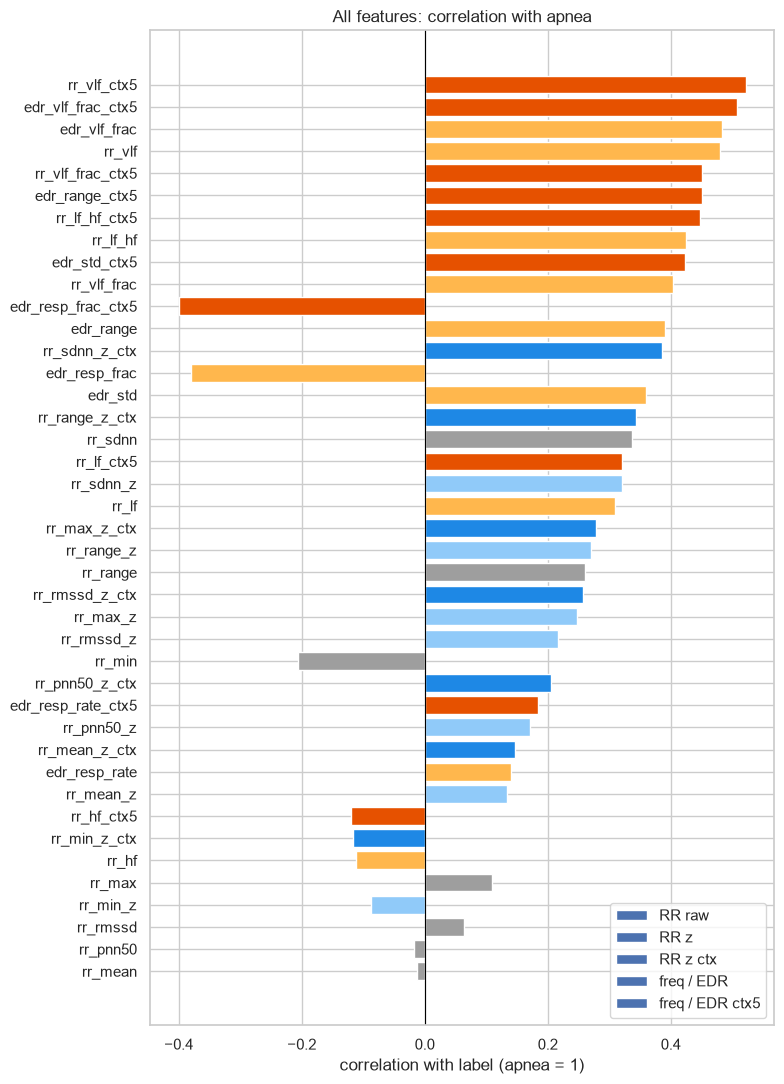

rr_vlf_ctx5          0.522
edr_vlf_frac_ctx5    0.508
edr_vlf_frac         0.483
rr_vlf               0.480
rr_vlf_frac_ctx5     0.451
edr_range_ctx5       0.451
rr_lf_hf_ctx5        0.448
rr_lf_hf             0.425
edr_std_ctx5         0.423
rr_vlf_frac          0.404
Name: label, dtype: float64

In [ ]:
ALL = BASE + Z + CTX + FREQ_COLS + FREQ_CTX
corr_y = train[ALL + ['label']].corr()['label'].drop('label')

kind = pd.Series('RR raw', index=ALL)
kind[Z] = 'RR z'; kind[CTX] = 'RR z ctx'; kind[FREQ_COLS] = 'freq / EDR'; kind[FREQ_CTX] = 'freq / EDR ctx5'
palette = {'RR raw': '#9e9e9e', 'RR z': '#90caf9', 'RR z ctx': '#1e88e5',
           'freq / EDR': '#ffb74d', 'freq / EDR ctx5': '#e65100'}

order = corr_y.abs().sort_values().index
plt.figure(figsize=(8, 11))
plt.barh(order, corr_y[order], color=kind[order].map(palette))
plt.axvline(0, color='black', lw=0.8)
for k, c in palette.items():
    plt.barh([], [], color=c, label=k)          # legend entries
plt.legend(loc='lower right'); plt.xlabel('correlation with label (apnea = 1)')
plt.title('All features: correlation with apnea')
plt.tight_layout()
plt.savefig(FIG / 'feature_label_correlation_all.png', dpi=150, bbox_inches='tight')
plt.show()

corr_y.reindex(corr_y.abs().sort_values(ascending=False).index).head(10).round(3)

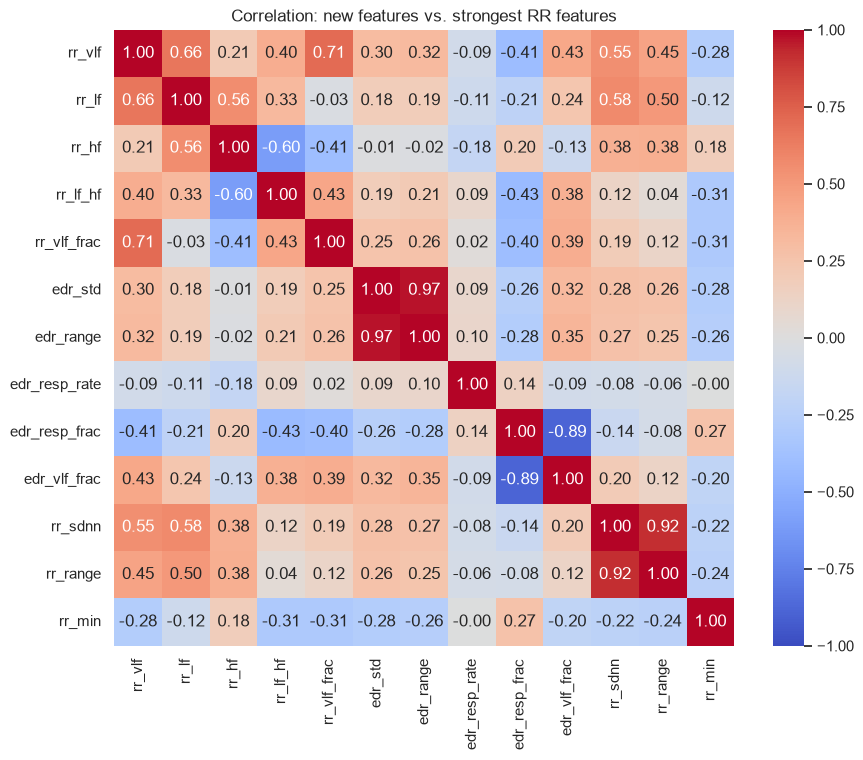

In [ ]:
plt.figure(figsize=(10, 8))
sns.heatmap(train[FREQ_COLS + ['rr_sdnn', 'rr_range', 'rr_min']].corr(),
            annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation: new features vs. strongest RR features')
plt.savefig(FIG / 'correlation_freq.png', dpi=150, bbox_inches='tight')
plt.show()

## ML Models

In [15]:
SETS = {
    'A': BASE,                          # 7  - raw per-minute RR statistics (SDNN/RMSSD log-transformed)
    'B': Z,                             # 7  - A z-scored within each patient (removes personal baseline)
    'C': Z + CTX,                       # 14 - B + 5-minute moving average of B (context of neighbouring minutes)
    'D': BASE + Z + CTX,                # 21 - all RR-based features (A + C)
    'E': Z + CTX + FREQ_COLS,           # 24 - C + frequency-domain HRV and ECG-derived respiration (EDR)
    'E+': Z + CTX + FREQ_COLS + FREQ_CTX,
    'E+z': Z + CTX + FREQ_Z + FREQ_ZCTX,
    'F': BASE + Z + CTX + FREQ_COLS,    # 31 - D + frequency-domain HRV and EDR (all features)
}

In [16]:
def run_ml_cv(model, feat_set, split_col='patient_fold', run_name=None, use_wandb=False):
    feats = SETS[feat_set]
    oof = np.zeros(len(train))
    for tr, va in get_cv_splits(train, split_col):
        m = clone(model).fit(train.iloc[tr][feats], train.iloc[tr]['label'])
        oof[va] = m.predict_proba(train.iloc[va][feats])[:, 1]

    split_type = 'patient_fold' if split_col == 'patient_fold' else 'random_fold'
    metrics = evaluate_and_log(train, oof, model_name=f'{run_name}_{feat_set}',
                               split_type=split_type,
                               config={'family': 'ML','model': run_name, 'features': feat_set, 'n_features': len(feats)},
                               use_wandb=use_wandb, wandb_project='apnea-ecg-ml')
    return oof, metrics

In [17]:
res = []
leak = []
def run_and_store(model, name, sets=('A', 'B', 'C', 'D', 'E','E+', 'E+z', 'F',), split_col = 'patient_fold', use_wandb = False, store=None):
    store = res if store is None else store
    for s in sets:
        _, m = run_ml_cv(model=model, feat_set=s, split_col=split_col,run_name=name,use_wandb=use_wandb)
        store.append({'model': name, 'set': s, 'split': split_col, **m})

#### Finding k on the best feature set E+

In [ ]:
cv = list(get_cv_splits(train, 'patient_fold'))

knn_grid = GridSearchCV(
    make_pipeline(StandardScaler(), KNeighborsClassifier()),
    param_grid={
        'kneighborsclassifier__n_neighbors': [5, 15, 31, 51, 101, 201],
        'kneighborsclassifier__weights': ['uniform', 'distance'],
    },
    scoring='roc_auc', cv = cv, n_jobs=-1,

)

knn_grid.fit(train[SETS['E+']],train['label'])
res_k =pd.DataFrame(knn_grid.cv_results_)
res_k = res_k[['param_kneighborsclassifier__n_neighbors', 'param_kneighborsclassifier__weights', 'mean_test_score', 'std_test_score']]

res_k.columns = ['k', 'weights', 'auc_mean', 'auc_std']
best_k = knn_grid.best_params_['kneighborsclassifier__n_neighbors']
best_w = knn_grid.best_params_['kneighborsclassifier__weights']
print(res_k.sort_values('auc_mean', ascending=False).round(3))
print('best:', knn_grid.best_params_)


      k   weights  auc_mean  auc_std
11  201  distance     0.914    0.046
10  201   uniform     0.914    0.046
9   101  distance     0.912    0.047
8   101   uniform     0.912    0.046
7    51  distance     0.908    0.048
6    51   uniform     0.908    0.048
5    31  distance     0.905    0.048
4    31   uniform     0.905    0.048
3    15  distance     0.896    0.050
2    15   uniform     0.896    0.050
0     5   uniform     0.873    0.052
1     5  distance     0.873    0.052
best: {'kneighborsclassifier__n_neighbors': 201, 'kneighborsclassifier__weights': 'distance'}


#### Model Training

In [ ]:
lr = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))
dtree = DecisionTreeClassifier(max_depth=6, min_samples_leaf=1, min_samples_split=2)
rf = RandomForestClassifier(n_estimators=400, min_samples_leaf=3,n_jobs = -1, random_state=42)
xgbt = XGBClassifier(n_estimators=300, max_depth=3, learning_rate=0.03, subsample=0.8,
    colsample_bytree=0.7,
    min_child_weight=25,
    reg_alpha=1.0,
    reg_lambda=10.0,
    eval_metric='logloss',
    random_state=42,n_jobs = -1)

knn = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=best_k, weights=best_w))
nb_power = make_pipeline(PowerTransformer(), GaussianNB())

MODELS = {
    'lr':lr,
    'dtree':dtree,
    'rf':rf,
    'xgb':xgbt,
    
    'knn':knn,
    'nb': nb_power,
}

for i, j in MODELS.items():
    run_and_store(j,i, use_wandb=False)

[patient_fold | lr_A] Acc=0.6846 Sens=0.7303 Spec=0.6549 F1=0.6459 AUC=0.7288 (thr=0.35, PatAcc=0.686)
[patient_fold | lr_B] Acc=0.6145 Sens=0.8309 Spec=0.4740 F1=0.6294 AUC=0.6993 (thr=0.32, PatAcc=0.657)
[patient_fold | lr_C] Acc=0.6578 Sens=0.8171 Spec=0.5543 F1=0.6529 AUC=0.7395 (thr=0.33, PatAcc=0.657)
[patient_fold | lr_D] Acc=0.7392 Sens=0.7027 Spec=0.7629 F1=0.6797 AUC=0.7787 (thr=0.40, PatAcc=0.686)
[patient_fold | lr_E] Acc=0.8195 Sens=0.8109 Spec=0.8250 F1=0.7797 AUC=0.8920 (thr=0.41, PatAcc=0.771)
[patient_fold | lr_E+] Acc=0.8384 Sens=0.8137 Spec=0.8545 F1=0.7987 AUC=0.9078 (thr=0.43, PatAcc=0.857)
[patient_fold | lr_E+z] Acc=0.6663 Sens=0.8114 Spec=0.5721 F1=0.6570 AUC=0.7566 (thr=0.32, PatAcc=0.657)
[patient_fold | lr_F] Acc=0.7855 Sens=0.7672 Spec=0.7974 F1=0.7380 AUC=0.8630 (thr=0.35, PatAcc=0.800)
[patient_fold | dtree_A] Acc=0.6703 Sens=0.7589 Spec=0.6128 F1=0.6445 AUC=0.6862 (thr=0.35, PatAcc=0.657)
[patient_fold | dtree_B] Acc=0.5902 Sens=0.8824 Spec=0.4003 F1=0.62

In [20]:
results = pd.DataFrame(res)
results.pivot_table(index='model', columns='set', values='roc_auc').round(3)

set,A,B,C,D,E,E+,E+z,F
model,,,,,,,,
dtree,0.686,0.695,0.726,0.676,0.861,0.852,0.774,0.841
knn,0.687,0.733,0.761,0.744,0.908,0.911,0.803,0.900
lr,0.729,0.699,0.739,0.779,0.892,0.908,0.757,0.863
nb,0.634,0.694,0.722,0.707,0.875,0.896,0.759,0.858
rf,0.697,0.742,0.786,0.741,0.911,0.913,0.844,0.901
xgb,0.691,0.729,0.766,0.723,0.915,0.920,0.823,0.904


In [21]:
pd.DataFrame(res).to_csv(ROOT / 'reports' / 'ml_init_results_patient.csv', index=False)

## Leakage Experiment

In [22]:
LEAK_MODELS = {
    'lr':lr,
    'dtree':dtree,
    'rf':rf,
    'xgb':xgbt,
    
    'knn':knn,
    'nb': nb_power,
}

for i, j in LEAK_MODELS.items():
    run_and_store(j,i, sets=('D', 'E+'), split_col='random_fold', use_wandb=False, store = leak)

[random_fold | lr_D] Acc=0.7861 Sens=0.7636 Spec=0.8007 F1=0.7377 AUC=0.8591 (thr=0.42, PatAcc=0.714)
[random_fold | lr_E+] Acc=0.8645 Sens=0.8453 Spec=0.8769 F1=0.8309 AUC=0.9318 (thr=0.45, PatAcc=0.914)
[random_fold | dtree_D] Acc=0.7658 Sens=0.8441 Spec=0.7150 F1=0.7396 AUC=0.8374 (thr=0.37, PatAcc=0.657)
[random_fold | dtree_E+] Acc=0.8652 Sens=0.8627 Spec=0.8668 F1=0.8344 AUC=0.9301 (thr=0.43, PatAcc=0.800)
[random_fold | rf_D] Acc=0.8776 Sens=0.8757 Spec=0.8787 F1=0.8493 AUC=0.9478 (thr=0.43, PatAcc=0.886)
[random_fold | rf_E+] Acc=0.9250 Sens=0.9270 Spec=0.9237 F1=0.9069 AUC=0.9783 (thr=0.43, PatAcc=0.971)
[random_fold | xgb_D] Acc=0.8221 Sens=0.8387 Spec=0.8113 F1=0.7879 AUC=0.9010 (thr=0.41, PatAcc=0.800)
[random_fold | xgb_E+] Acc=0.8976 Sens=0.8824 Spec=0.9076 F1=0.8716 AUC=0.9605 (thr=0.47, PatAcc=0.943)
[random_fold | knn_D] Acc=0.8013 Sens=0.8544 Spec=0.7669 F1=0.7721 AUC=0.8890 (thr=0.41, PatAcc=0.714)
[random_fold | knn_E+] Acc=0.8751 Sens=0.8933 Spec=0.8634 F1=0.8493 A

In [23]:
results_leak = pd.DataFrame(leak)
results_leak.pivot_table(index='model', columns='set', values='roc_auc').round(3)

set,D,E+
model,,
dtree,0.837,0.930
knn,0.889,0.952
lr,0.859,0.932
nb,0.739,0.909
rf,0.948,0.978
xgb,0.901,0.961


In [24]:
pd.DataFrame(leak).to_csv(ROOT / 'reports' / 'ml_init_results_random.csv', index=False)

#### Differences


In [ ]:
cols = ['model', 'set', 'roc_auc', 'accuracy']

leak_table = (results[cols].merge(results_leak[cols], on=['model', 'set'], suffixes=('_patient', '_random')))
leak_table['auc_gap'] = leak_table.roc_auc_random - leak_table.roc_auc_patient
leak_table['acc_gap'] = leak_table.accuracy_random - leak_table.accuracy_patient
leak_table = leak_table.sort_values(['set', 'auc_gap'], ascending=[True, False]).round(3)
leak_table

,model,set,roc_auc_patient,accuracy_patient,roc_auc_random,accuracy_random,auc_gap,acc_gap
4,rf,D,0.741,0.653,0.948,0.878,0.207,0.225
6,xgb,D,0.723,0.665,0.901,0.822,0.178,0.157
2,dtree,D,0.676,0.664,0.837,0.766,0.161,0.102
8,knn,D,0.744,0.656,0.889,0.801,0.145,0.146
0,lr,D,0.779,0.739,0.859,0.786,0.080,0.047
10,nb,D,0.707,0.626,0.739,0.647,0.032,0.021
3,dtree,E+,0.852,0.797,0.930,0.865,0.078,0.068
5,rf,E+,0.913,0.839,0.978,0.925,0.066,0.086
9,knn,E+,0.911,0.832,0.952,0.875,0.041,0.043
7,xgb,E+,0.920,0.850,0.961,0.898,0.040,0.048


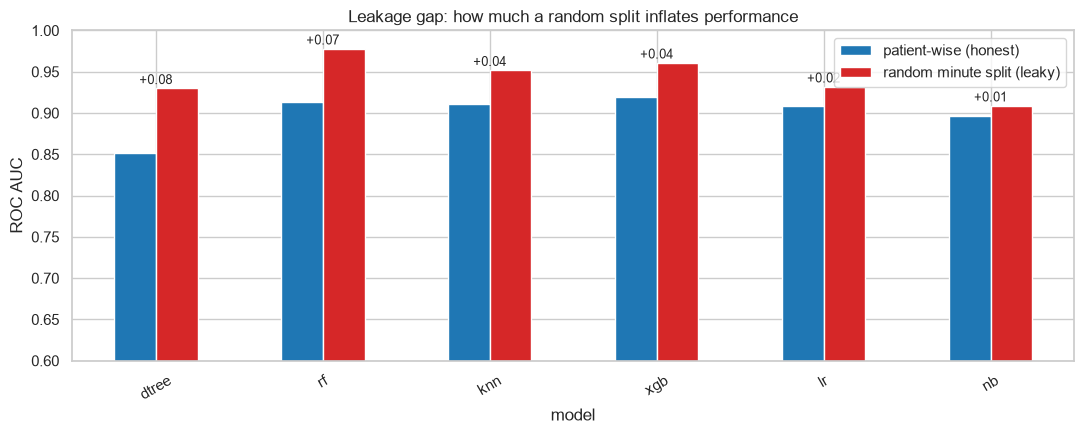

In [ ]:
d = leak_table[leak_table.set.isin(['E+'])].set_index('model')
ax = d[['roc_auc_patient', 'roc_auc_random']].plot.bar(figsize=(11, 4.5), rot=30, color=['#1f77b4', '#d62728'])
for i, gap in enumerate(d.auc_gap):
    ax.text(i, d.roc_auc_random.iloc[i] + 0.005, f'+{gap:.2f}', ha='center', fontsize=9)
ax.set_ylim(0.6, 1.0); ax.set_ylabel('ROC AUC')
ax.legend(['patient-wise (honest)', 'random minute split (leaky)'])
ax.set_title('Leakage gap: how much a random split inflates performance')
plt.tight_layout()
plt.savefig(FIG / 'leakage_gap_all.png', dpi=150, bbox_inches='tight')
plt.show()

## Feature Importance

In [34]:
FI_SET = 'E+'
feats = SETS['E+']
fi_model = MODELS['xgb'] #or random forest

fitted = []
for tr , va in get_cv_splits(train,'patient_fold'): #training row | validation row
    m = clone(fi_model).fit(train.iloc[tr][feats], train.iloc[tr]['label'])
    fitted.append((m,va))


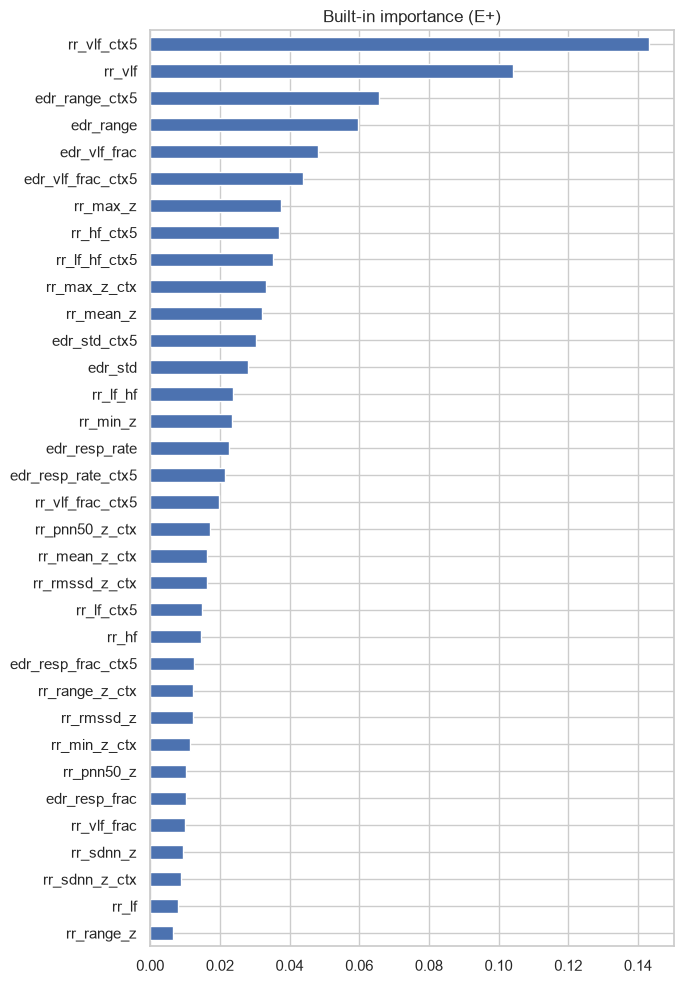

rr_vlf_ctx5          0.143
rr_vlf               0.104
edr_range_ctx5       0.066
edr_range            0.060
edr_vlf_frac         0.048
edr_vlf_frac_ctx5    0.044
rr_max_z             0.038
rr_hf_ctx5           0.037
rr_lf_hf_ctx5        0.035
rr_max_z_ctx         0.033
dtype: float32

In [35]:
# built in importance
imp = np.mean([m.feature_importances_ for m, _ in fitted], axis=0)
builtin = pd.Series(imp, index=feats).sort_values()

plt.figure(figsize=(7, 10)); builtin.plot.barh()
plt.title(f"Built-in importance ({FI_SET})"); plt.tight_layout()
plt.savefig(FIG / "fi_builtin.png", dpi=150, bbox_inches="tight"); plt.show()
builtin.sort_values(ascending=False).head(10).round(3)

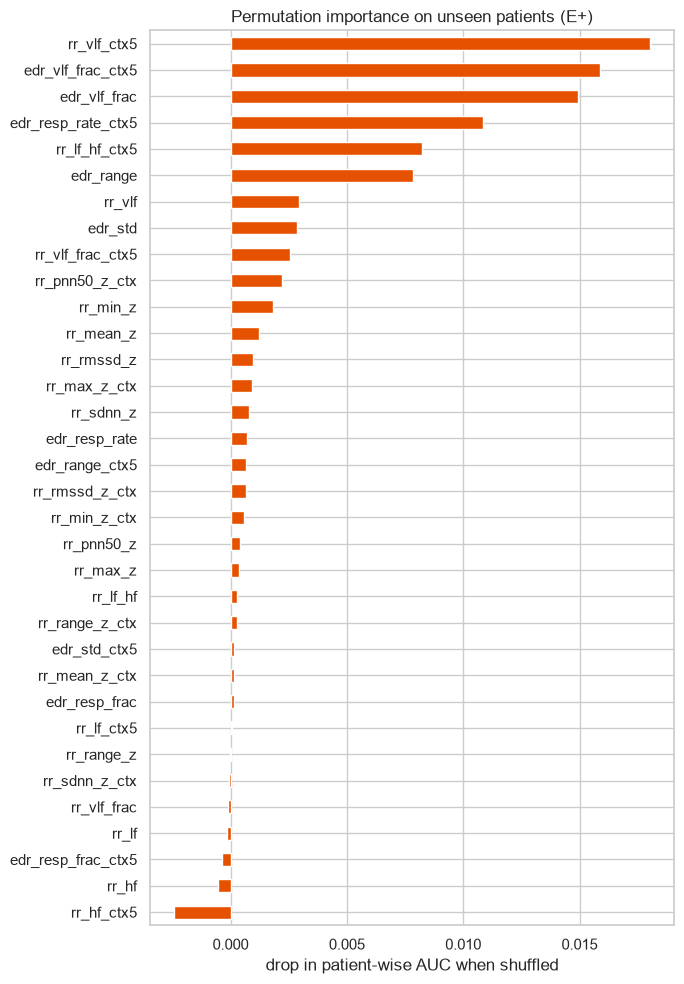

rr_vlf_ctx5           0.0180
edr_vlf_frac_ctx5     0.0159
edr_vlf_frac          0.0150
edr_resp_rate_ctx5    0.0108
rr_lf_hf_ctx5         0.0082
edr_range             0.0078
rr_vlf                0.0029
edr_std               0.0029
rr_vlf_frac_ctx5      0.0026
rr_pnn50_z_ctx        0.0022
dtype: float64

In [ ]:
#permutation importance on unseen patients
from sklearn.inspection import permutation_importance

perm = []
for m, va in fitted:
    r = permutation_importance(m, train.iloc[va][feats], train.iloc[va]["label"],
                               scoring="roc_auc", n_repeats=5, random_state=42, n_jobs=-1)
    perm.append(r.importances_mean)
perm = pd.Series(np.mean(perm, axis=0), index=feats).sort_values()

plt.figure(figsize=(7, 10)); perm.plot.barh(color="#e65100")
plt.xlabel("drop in patient-wise AUC when shuffled")
plt.title(f"Permutation importance on unseen patients ({FI_SET})"); plt.tight_layout()
plt.savefig(FIG / "fi_permutation.png", dpi=150, bbox_inches="tight"); plt.show()
perm.sort_values(ascending=False).head(10).round(4)

#### GridSearch for XGB and RF

In [37]:
cv = list(get_cv_splits(train, "patient_fold"))
X, y = train[SETS["E+"]], train["label"]

xgb_grid = GridSearchCV(
    XGBClassifier(n_estimators=300, subsample=0.8, colsample_bytree=0.8,
                  random_state=42, n_jobs=-1, eval_metric="logloss"),
    param_grid={"max_depth": [2, 3, 5],
                "learning_rate": [0.03, 0.1, 0.3],
                "min_child_weight": [1, 10]},
    scoring="roc_auc", cv=cv, verbose=1)

xgb_grid.fit(X, y)
print("XGB best:", xgb_grid.best_params_, round(xgb_grid.best_score_, 4))



rf_grid = GridSearchCV(
    RandomForestClassifier(n_estimators=300, n_jobs=-1, random_state=42),
    param_grid={"max_depth": [6, 12, None],
                "min_samples_leaf": [5, 20, 50]},
    scoring="roc_auc", cv=cv, verbose=1)
rf_grid.fit(X, y)

print("RF best:", rf_grid.best_params_, round(rf_grid.best_score_, 4))

Fitting 5 folds for each of 18 candidates, totalling 90 fits
XGB best: {'learning_rate': 0.1, 'max_depth': 2, 'min_child_weight': 10} 0.9271
Fitting 5 folds for each of 9 candidates, totalling 45 fits
RF best: {'max_depth': 12, 'min_samples_leaf': 5} 0.9151


In [38]:
run_and_store(xgb_grid.best_estimator_, "xgb_tuned", sets=("E+",), use_wandb=False)
run_and_store(rf_grid.best_estimator_, "rf_tuned", sets=("E+",), use_wandb=False)

[patient_fold | xgb_tuned_E+] Acc=0.8522 Sens=0.8195 Spec=0.8734 F1=0.8137 AUC=0.9239 (thr=0.43, PatAcc=0.857)
[patient_fold | rf_tuned_E+] Acc=0.8457 Sens=0.7822 Spec=0.8870 F1=0.7998 AUC=0.9135 (thr=0.45, PatAcc=0.800)


## Final Model Choice
Final Model xgb tuned

In [43]:
final_model = clone(xgb_grid.best_estimator_).fit(train[SETS["E+"]], train["label"])
joblib.dump(final_model, ROOT / "models" / "final_xgb.joblib")

['c:\\dev\\apnea-ecg-ml\\models\\final_xgb.joblib']